In [14]:
import torch
import numpy as np 
import matplotlib.pyplot as plt
import os
import sys
import joblib

sys.path.insert(0, os.path.abspath("../../.."))
sys.path.insert(0, os.path.abspath("../.."))

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA 
from cartpole_wind import cartpole_model_factory, make_envs, sample_tasks_eval, sample_tasks_train
from utils.evaluation import run_meta_eval 


In [15]:
# Generate 20 evaluation tasks with different wind strengths (-5 to +5)
env_configs = sample_tasks_eval(num_envs=20)

# Create 20 parallel CartPole environments based on these configurations
envs = make_envs(env_configs)

In [16]:
# Initialize the RL2 actor-critic model with a GRU based feature extractor
model = cartpole_model_factory()

In [17]:
# Load the checkpoint containing the trained model weights from the checkpoint onto the CPU
checkpoint_path = os.path.join("..", "..", "..", "checkpoints", "cartpole_wind.pt")
checkpoint = torch.load(checkpoint_path, map_location=torch.device("cpu"))

In [18]:
# Load the trained model weights supporting both checkpoint formats
if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:

num_envs = len(env_configs)
steps_per_env = 3000
model.eval()

# Reset all environments and get their initial observations
obs, _ = envs.reset()

# Initialize the hidden states with zeros
hidden_state = torch.zeros(1, num_envs, model.feat_extractor.h_dim)

# Initialize previous actions and rewards
prev_action = torch.zeros(num_envs, dtype=torch.long)
prev_reward = torch.zeros(num_envs, 1)
prev_done = torch.ones(num_envs, 1)

# Store the hidden states separately for each environment
env_hidden_accumulator = [[] for _ in range(num_envs)]

# Collect hidden states during interaction with the environments
with torch.no_grad():
    for step in range(steps_per_env):
        logits, values, hidden_state = model(
            torch.tensor(obs).view(1, num_envs, -1).float(),
            prev_action.view(1, num_envs),
            prev_reward.view(1, num_envs, -1).float(),
            prev_done.view(1, num_envs, 1),
            hidden_state
        )

        current_h = hidden_state.squeeze(0).cpu().numpy()

        for i in range(num_envs):
            env_hidden_accumulator[i].append(current_h[i])

        actions = torch.argmax(logits, dim=-1)
        actions_env = actions.squeeze(0).cpu().numpy()

        obs, reward, terminated, truncated, info = envs.step(actions_env)

        prev_action = actions
        prev_reward = torch.tensor(reward).unsqueeze(1).float()

        # Update done flags for the next step
        done = np.logical_or(terminated, truncated)
        prev_done = torch.tensor(done, dtype=torch.float32).unsqueeze(1)


In [21]:
# Calculate the average hidden state for each environment
avg_hidden_states = np.array([
    np.mean(h, axis=0) for h in env_hidden_accumulator
])

print(avg_hidden_states.shape)

(20, 64)


In [22]:
# Apply KMeans clustering to the average hidden states
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(avg_hidden_states)

# Save the original cluster assignments
np.save("../../../checkpoints/cartpole_wind_cluster_labels.npy", cluster_labels)

# Save the fitted K-Means model
joblib.dump(kmeans, "../../../checkpoints/cartpole_wind_kmeans.joblib")

print(cluster_labels)

[1 1 1 1 1 1 1 1 1 2 1 1 2 2 2 2 2 0 0 0]


In [23]:
# Display the wind and assigned cluster for each environment
for i, cfg in enumerate(env_configs):
    print(f"Environment {i}: Wind = {cfg['wind_mag']:.2f}, Cluster = {cluster_labels[i]}")

Environment 0: Wind = -5.00, Cluster = 1
Environment 1: Wind = -4.47, Cluster = 1
Environment 2: Wind = -3.95, Cluster = 1
Environment 3: Wind = -3.42, Cluster = 1
Environment 4: Wind = -2.89, Cluster = 1
Environment 5: Wind = -2.37, Cluster = 1
Environment 6: Wind = -1.84, Cluster = 1
Environment 7: Wind = -1.32, Cluster = 1
Environment 8: Wind = -0.79, Cluster = 1
Environment 9: Wind = -0.26, Cluster = 2
Environment 10: Wind = 0.26, Cluster = 1
Environment 11: Wind = 0.79, Cluster = 1
Environment 12: Wind = 1.32, Cluster = 2
Environment 13: Wind = 1.84, Cluster = 2
Environment 14: Wind = 2.37, Cluster = 2
Environment 15: Wind = 2.89, Cluster = 2
Environment 16: Wind = 3.42, Cluster = 2
Environment 17: Wind = 3.95, Cluster = 0
Environment 18: Wind = 4.47, Cluster = 0
Environment 19: Wind = 5.00, Cluster = 0


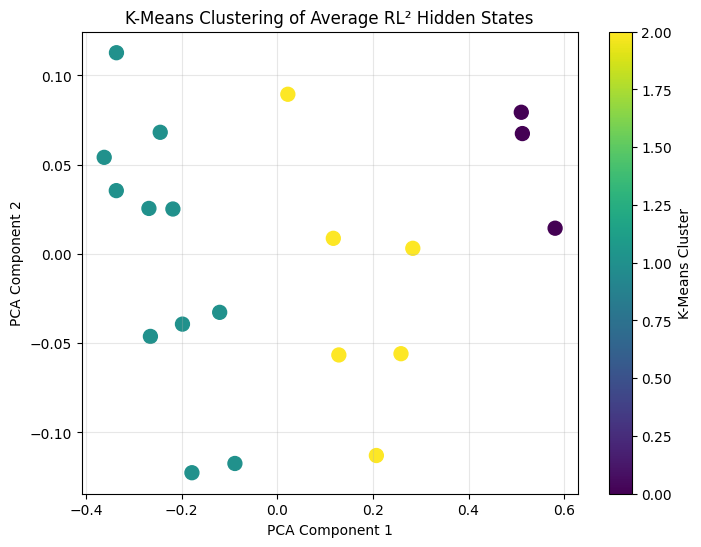

In [24]:
# Reduce the 64 dim average hidden states to 2 dim using PCA
pca = PCA(n_components=2)
reduced_h = pca.fit_transform(avg_hidden_states)

# Save the fitted PCA model
joblib.dump(pca, "../../../checkpoints/cartpole_wind_pca.joblib")

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    reduced_h[:, 0],
    reduced_h[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=100
)

plt.colorbar(scatter, label="K-Means Cluster")
plt.title("K-Means Clustering of Average RL² Hidden States")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(alpha=0.3)

plt.show()

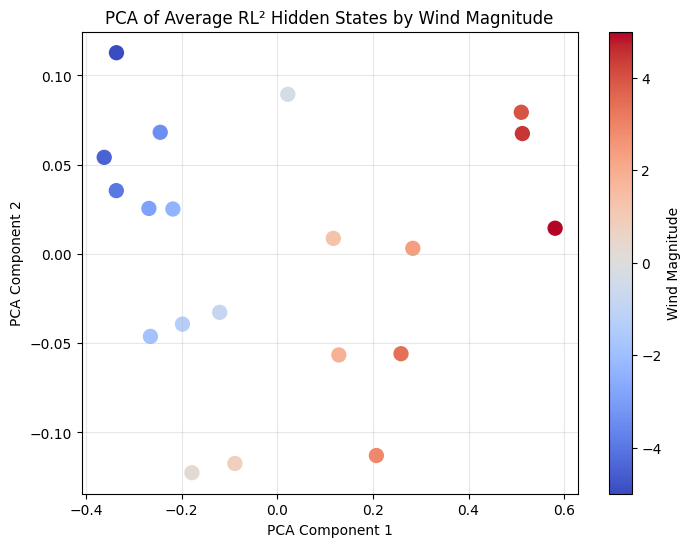

In [25]:
# Extract the wind for each environment
wind_values = [cfg["wind_mag"] for cfg in env_configs]

# Visualize the average hidden states colored by wind
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    reduced_h[:, 0],
    reduced_h[:, 1],
    c=wind_values,
    cmap="coolwarm",
    s=100
)

plt.colorbar(scatter, label="Wind Magnitude")
plt.title("PCA of Average RL² Hidden States by Wind Magnitude")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(alpha=0.3)

plt.show()